# Experiment 1: Exploratory Data Analysis

This notebook reads every `outputs/<format>/comparison<n>.csv` written by `compare.py`, where each row is one ground truth paired with one extracted business rule.

Run it from the folder that contains `outputs/`. Rows where every LLM score is zero are removed before any of the analysis.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display

OUTPUT_FOLDER = 'outputs'
GROUP_BY = 'file'       #'file' groups by documentation file (.rst), 'rule_file' groups by code file (.py)

LLM_PASSES = ['llm_score_1', 'llm_score_2', 'llm_score_3']
LLM_COLUMNS = LLM_PASSES + ['llm_score']
METRICS = {'cosine': 'Cosine', 'meteor': 'METEOR', 'rouge1_fmeasure': 'ROUGE-1 F', 'rouge2_fmeasure': 'ROUGE-2 F',
           'rougeL_fmeasure': 'ROUGE-L F', 'bert_f1': 'BERT F1', 'llm_score': 'LLM'}
KEYS = ['prompt_format', 'iteration']

#Chart styling: one fixed colour per metric, and quiet gridlines and axes
COLOURS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#4a3aa7']
SURFACE, INK, SECONDARY, MUTED, GRID, AXIS = '#fcfcfb', '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'

plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE, 'figure.dpi': 110,
    'font.family': 'sans-serif', 'font.size': 10, 'text.color': INK,
    'axes.edgecolor': AXIS, 'axes.labelcolor': SECONDARY, 'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'axes.axisbelow': True,
    'grid.color': GRID, 'grid.linewidth': 0.8, 'grid.linestyle': '-',
    'xtick.color': MUTED, 'ytick.color': MUTED, 'xtick.labelcolor': SECONDARY, 'ytick.labelcolor': SECONDARY,
    'lines.linewidth': 2, 'lines.markersize': 7, 'lines.markeredgewidth': 1.5, 'lines.markeredgecolor': SURFACE,
    'legend.frameon': False})

pd.set_option('display.max_colwidth', 80)

## 1. Load the comparison files

In [2]:
def file_number(path: Path) -> int:
    #comparison2.csv -> 2
    return int(re.search(r'(\d+)$', path.stem).group(1))

def load_comparisons(folder: str) -> pd.DataFrame:
    #Reads every comparison file into one table, tagged with its prompt format and iteration
    paths = sorted(Path(folder).glob('*/comparison*.csv'))
    if not paths:
        raise FileNotFoundError(f'No comparison files found in {folder}/<format>/')
    frames = [pd.read_csv(path).assign(prompt_format = path.parent.name, iteration = file_number(path)) for path in paths]
    return pd.concat(frames, ignore_index = True)

raw = load_comparisons(OUTPUT_FOLDER)
PROMPT_FORMATS = sorted(raw['prompt_format'].unique())
ITERATIONS = sorted(raw['iteration'].unique())

print(f'{len(raw)} rows from {raw.groupby(KEYS).ngroups} files')
raw.head(3)

6852 rows from 8 files


,file,ground_truth,business_rule,rule_file,cosine,meteor,rouge1_precision,rouge1_recall,rouge1_fmeasure,rouge2_precision,...,bert_precision,bert_recall,bert_f1,llm_score_1,llm_score_2,llm_score_3,llm_score,llm_reason,prompt_format,iteration
0,config.rst,Only uppercase variable names in a Python config file get loaded into the ap...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,cobrex,0
1,config.rst,You shouldn't turn DEBUG on or off through code or config at runtime. Use th...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,cobrex,0
2,config.rst,"When TESTING is on, exceptions get re-raised instead of being caught by the ...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,cobrex,0


## 2. Remove the rows where every LLM score is zero

Three sets of rows are kept apart:

- `unpaired`: ground truths that had no business rules to compare against (their rule and scores are empty).
- `pairs`: every ground truth and business rule pair that was scored.
- `data`: the pairs left after removing those where all of the LLM scores are zero. **Everything after section 3 uses `data`.**

In [3]:
unpaired = raw[raw['business_rule'].isna()]
pairs = raw.dropna(subset = ['business_rule'])

all_zero = (pairs[LLM_COLUMNS] == 0).all(axis = 1)
data = pairs[~all_zero]

print(f'{len(pairs)} scored pairs, {all_zero.sum()} removed for all-zero LLM scores ({all_zero.mean():.0%}), {len(data)} kept')

6748 scored pairs, 5708 removed for all-zero LLM scores (85%), 1040 kept


## 3. Basic information on each file

One row per comparison file. The two "ground truths without" columns mean different things:

- **no rules to compare**: no business rules were extracted from the code files mapped to that ground truth's documentation file.
- **only zero LLM scores**: rules existed, but every one of them scored zero on the LLM evaluator, so the filter removed them all.

In [4]:
def per_file(frame: pd.DataFrame, column: str = None) -> pd.Series:
    #Counts rows, or unique values of a column, for every prompt format and iteration
    grouped = frame.groupby(KEYS)
    return grouped[column].nunique() if column else grouped.size()

info = pd.DataFrame({
    'ground_truths': per_file(raw, 'ground_truth'),
    'no_rules_to_compare': per_file(unpaired, 'ground_truth'),
    'pairs': per_file(pairs),
    'pairs_removed': per_file(pairs[all_zero]),
    'pairs_kept': per_file(data),
    'truths_with_a_kept_pair': per_file(data, 'ground_truth'),
}).fillna(0).astype(int)

info['only_zero_llm_scores'] = info['ground_truths'] - info['no_rules_to_compare'] - info['truths_with_a_kept_pair']
info['removed_%'] = (100 * info['pairs_removed'] / info['pairs']).round(1)
info = info[['ground_truths', 'no_rules_to_compare', 'only_zero_llm_scores', 'pairs', 'pairs_removed', 'removed_%', 'pairs_kept']]
info

ground_truths  no_rules_to_compare  \
prompt_format iteration                                       
cobrex        0                     34                   13   
              1                     34                   13   
              2                     34                   13   
              3                     34                   13   
user_story    0                     34                   13   
              1                     34                   13   
              2                     34                   13   
              3                     34                   13   

                         only_zero_llm_scores  pairs  pairs_removed  \
prompt_format iteration                                               
cobrex        0                             8    871            770   
              1                             8    887            796   
              2                             4    887            789   
              3                             4    903            791   
user_story    0                             3    770            625   
              1                             1    786            622   
              2                             3    810            650   
              3                             1    834            665   

                         removed_%  pairs_kept  
prompt_format iteration                         
cobrex        0               88.4         101  
              1               89.7          91  
              2               89.0          98  
              3               87.6         112  
user_story    0               81.2         145  
              1               79.1         164  
              2               80.2         160  
              3               79.7         169

Which documentation files the unmatched ground truths come from:

In [5]:
if unpaired.empty:
    print('Every ground truth had at least one business rule to compare against.')
else:
    display(unpaired.pivot_table(index = ['prompt_format', 'file'], columns = 'iteration', values = 'ground_truth',
                                 aggfunc = 'nunique', fill_value = 0))

,iteration,0,1,2,3
prompt_format,file,,,,
cobrex,config.rst,13,13,13,13
user_story,config.rst,13,13,13,13


## 4. Number of rules vs number of iterations

Counted from the `br<n>.csv` files, so it includes every extracted rule, before any filtering.

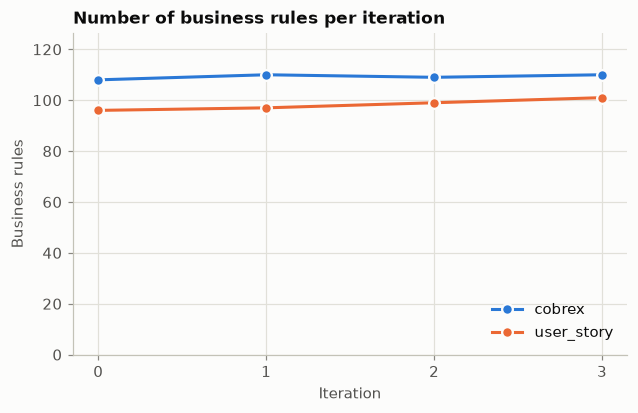

prompt_format,cobrex,user_story
iteration,,
0,108,96
1,110,97
2,109,99
3,110,101


In [6]:
def count_rules(folder: str) -> pd.DataFrame:
    #Number of extracted business rules for every prompt format and iteration
    rows = [{'prompt_format': path.parent.name, 'iteration': file_number(path), 'rules': len(pd.read_csv(path))}
            for path in sorted(Path(folder).glob('*/br*.csv'))]
    if not rows:
        #No br files here, so count the distinct rules that appear in the comparison files instead
        return pairs.drop_duplicates(KEYS + ['rule_file', 'business_rule']).groupby(KEYS).size().rename('rules').reset_index()
    return pd.DataFrame(rows)

rule_counts = count_rules(OUTPUT_FOLDER).pivot(index = 'iteration', columns = 'prompt_format', values = 'rules')

fig, ax = plt.subplots(figsize = (6.5, 3.8))
for colour, prompt_format in zip(COLOURS, rule_counts.columns):
    series = rule_counts[prompt_format].dropna()
    ax.plot(series.index, series.values, marker = 'o', color = colour, label = prompt_format)

ax.set_title('Number of business rules per iteration')
ax.set_xlabel('Iteration')
ax.set_ylabel('Business rules')
ax.set_xticks(rule_counts.index)
ax.set_ylim(0, rule_counts.max().max() * 1.15)
ax.legend(loc = 'lower right')
plt.show()

rule_counts

In [7]:
#The same count split by code file
rules_by_file = pairs.drop_duplicates(KEYS + ['rule_file', 'business_rule']).pivot_table(
    index = ['prompt_format', 'rule_file'], columns = 'iteration', values = 'business_rule', aggfunc = 'count', fill_value = 0)
rules_by_file

iteration                     0   1   2   3
prompt_format rule_file                    
cobrex        __init__.py     5   8   6   6
              app.py         18  18  18  18
              blueprints.py   5   5   6   7
              cli.py         14  14  14  14
              ctx.py         11  11  11  11
              provider.py    16  16  16  16
              sessions.py    16  16  16  16
              signals.py     11  11  11  11
              testing.py     12  11  11  11
user_story    __init__.py     5   5   5   5
              app.py         19  19  19  19
              blueprints.py   4   5   6   7
              cli.py         10  10  10  10
              ctx.py          9   9   9   9
              provider.py    11  11  12  13
              sessions.py    18  18  18  18
              signals.py     10  10  10  10
              testing.py     10  10  10  10

## 5. Highest scores for each file per iteration

The best single pair in each file, after the zero filter. Change `GROUP_BY` in the first cell to `'rule_file'` to group by code file instead of documentation file. A blank cell means that file had no pairs left in that iteration.

In [8]:
def highest(column: str) -> pd.DataFrame:
    #Highest value of a score for every file, with one column per iteration
    return data.pivot_table(index = ['prompt_format', GROUP_BY], columns = 'iteration', values = column, aggfunc = 'max').round(3)

print('Highest cosine similarity')
display(highest('cosine'))

print('Highest LLM score (final pass)')
display(highest('llm_score'))

Highest cosine similarity


iteration                         0      1      2      3
prompt_format file                                      
cobrex        api.rst         0.785  0.785  0.732  0.732
              blueprints.rst  0.490  0.494  0.511  0.497
              signals.rst     0.722  0.726  0.734  0.734
user_story    api.rst         0.711  0.711  0.711  0.711
              blueprints.rst  0.628  0.683  0.643  0.643
              signals.rst     0.748  0.698  0.688  0.688

Highest LLM score (final pass)


iteration                        0    1    2     3
prompt_format file                                
cobrex        api.rst         0.75  0.9  0.9  0.80
              blueprints.rst  0.50  0.5  0.5  0.50
              signals.rst     0.40  0.4  0.5  0.50
user_story    api.rst         0.60  0.6  0.6  0.60
              blueprints.rst  0.50  0.6  0.6  0.65
              signals.rst     0.20  0.5  0.4  0.40

In [9]:
#The pair behind each highest LLM score in the last iteration
last = data[data['iteration'] == ITERATIONS[-1]]
top = last.loc[last.groupby(['prompt_format', GROUP_BY])['llm_score'].idxmax()]
top[['prompt_format', GROUP_BY, 'ground_truth', 'business_rule', 'cosine', 'llm_score']].reset_index(drop = True)

,prompt_format,file,ground_truth,business_rule,cosine,llm_score
0,cobrex,api.rst,"Flask's session object doesn't notice when you mutate something in place, li...",The modified flag for a session must be set to True whenever session data is...,0.511632,0.80
1,cobrex,blueprints.rst,A blueprint's static folder only works if it has a url_prefix set. Without o...,"The 'static_folder' must be set to serve static files; otherwise, a RuntimeE...",0.497490,0.50
2,cobrex,signals.rst,"Proxies like g, request, and session are only guaranteed to work between the...","The signal 'request-started' signifies the beginning of request processing, ...",0.519531,0.50
3,user_story,api.rst,"request, session, g, and current_app are all proxies tied to a context. They...","As an application, I want to maintain a proper stack for application and req...",0.496585,0.60
4,user_story,blueprints.rst,A blueprint's static folder only works if it has a url_prefix set. Without o...,"Static files must be served using the configured static URL path, ensuring c...",0.553666,0.65
5,user_story,signals.rst,"Signals are meant for observing what's happening, not for changing it. Subsc...",The 'request-tearing-down' signal indicates that the context of a request is...,0.313191,0.40


### Top 5 pairs by LLM score, per iteration

The five highest-scoring pairs in each comparison file, printed in full. Pairs with the same LLM score are ordered by cosine similarity. Change `TOP_N` to print more or fewer.

In [10]:
import textwrap

TOP_N = 5

def print_field(label: str, text: str) -> None:
    #Prints one labelled piece of text, wrapped so it can be read without scrolling sideways
    print(textwrap.fill(str(text), width = 110, initial_indent = f'   {label:<15}', subsequent_indent = ' ' * 18))

def print_top_pairs(count: int = TOP_N) -> None:
    #Prints the highest LLM score pairs in full for every prompt format and iteration
    for (prompt_format, iteration), group in data.groupby(KEYS):
        print(f'\n{"=" * 110}\n{prompt_format}, iteration {iteration}: top {count} pairs by LLM score\n{"=" * 110}')
        top = group.sort_values(['llm_score', 'cosine'], ascending = False).head(count)

        for rank, (_, pair) in enumerate(top.iterrows(), start = 1):
            print(f'\n{rank}. LLM score {pair["llm_score"]:.2f}   cosine {pair["cosine"]:.3f}   {pair["file"]} vs {pair["rule_file"]}')
            print_field('Ground truth:', pair['ground_truth'])
            print_field('Business rule:', pair['business_rule'])
            if isinstance(pair.get('llm_reason'), str):
                print_field('LLM reason:', pair['llm_reason'])

print_top_pairs()


cobrex, iteration 0: top 5 pairs by LLM score

1. LLM score 0.75   cosine 0.520   api.rst vs sessions.py
   Ground truth:  Flask's session object doesn't notice when you mutate something in place, like appending to
                  a list. You need to manually set session.modified = True when that happens.
   Business rule: The modified flag for a session must be set to True when data in the session is changed.
   LLM reason:    Both statements convey the necessity of setting a modified flag when session data changes,
                  but Statement A provides additional context about in-place mutations, making it slightly
                  more specific than Statement B.

2. LLM score 0.60   cosine 0.785   api.rst vs sessions.py
   Ground truth:  Sessions are stored in a signed cookie that normally disappears when the browser closes.
                  Setting permanent to True keeps it alive for as long as PERMANENT_SESSION_LIFETIME says.
   Business rule: A session is permanent if 

## 6. Mean and median score for each metric vs number of iterations

All seven metrics share one 0 to 1 axis. Each figure has a row of panels for the mean and a row for the median, with one column per prompt format. The table under each figure puts the mean and median of every metric side by side.

The first figure summarises **every kept pair**. Most pairs put a ground truth next to a rule about something else, so these numbers mostly reflect unrelated pairs and move when the number of rules changes.

The second figure takes, for each ground truth, its **best-scoring rule** on each metric and summarises those. It is closer to "how well was each ground truth covered".

The LLM scores come in steps, so the LLM median moves in jumps where the mean moves smoothly. A mean well above the median means a few high-scoring pairs are pulling the average up.

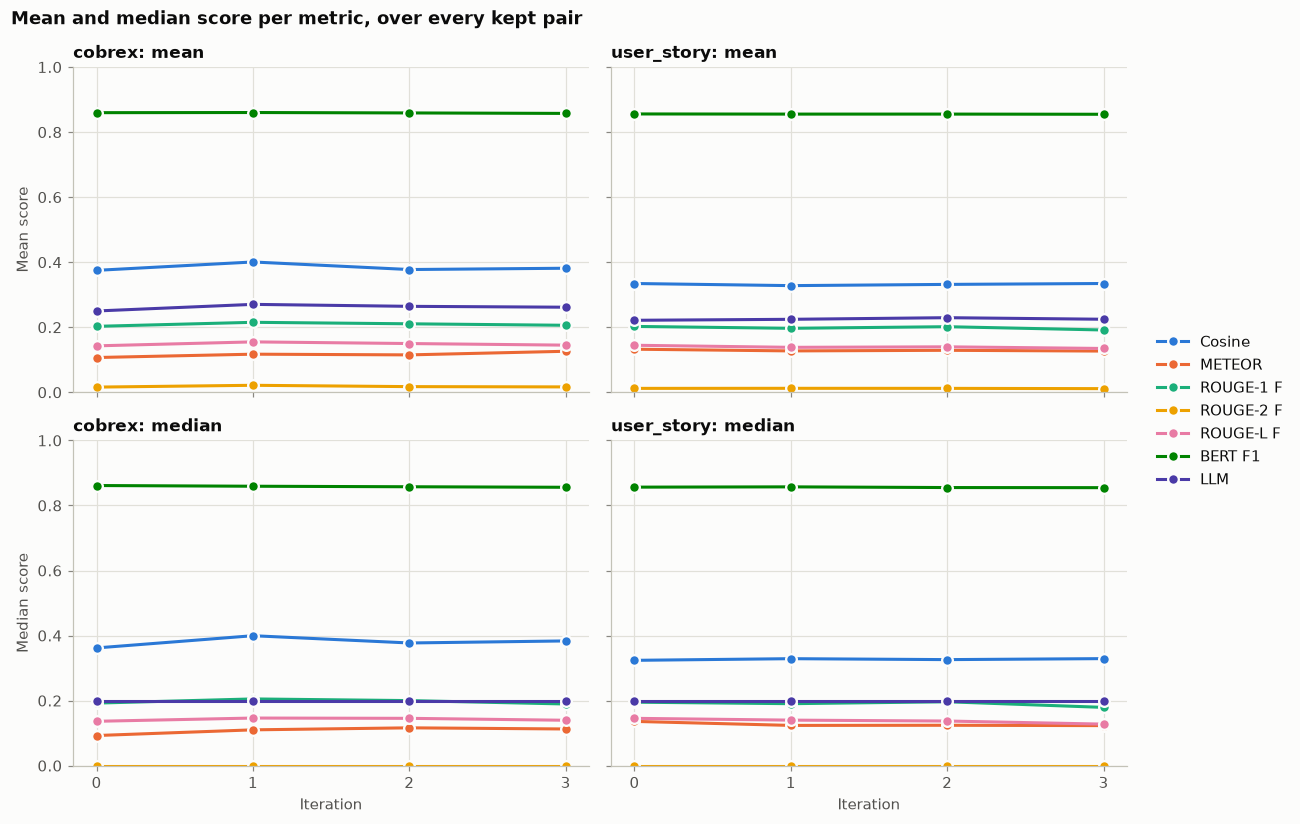

Cosine        METEOR        ROUGE-1 F         \
                          mean median   mean median      mean median   
prompt_format iteration                                                
cobrex        0          0.375  0.362  0.107  0.093     0.203  0.192   
              1          0.401  0.400  0.117  0.110     0.215  0.205   
              2          0.377  0.377  0.115  0.116     0.211  0.200   
              3          0.381  0.383  0.126  0.113     0.206  0.190   
user_story    0          0.334  0.324  0.132  0.136     0.203  0.195   
              1          0.328  0.329  0.127  0.124     0.197  0.190   
              2          0.332  0.326  0.129  0.124     0.202  0.196   
              3          0.335  0.329  0.127  0.123     0.192  0.179   

                        ROUGE-2 F        ROUGE-L F        BERT F1         \
                             mean median      mean median    mean median   
prompt_format iteration                                                    
cobrex        0             0.016    0.0     0.143  0.136   0.860  0.861   
              1             0.021    0.0     0.155  0.146   0.860  0.859   
              2             0.017    0.0     0.150  0.145   0.859  0.858   
              3             0.017    0.0     0.145  0.140   0.858  0.856   
user_story    0             0.012    0.0     0.145  0.145   0.856  0.856   
              1             0.012    0.0     0.138  0.140   0.855  0.857   
              2             0.012    0.0     0.140  0.137   0.855  0.855   
              3             0.011    0.0     0.135  0.128   0.855  0.855   

                           LLM         
                          mean median  
prompt_format iteration                
cobrex        0          0.250    0.2  
              1          0.270    0.2  
              2          0.264    0.2  
              3          0.262    0.2  
user_story    0          0.221    0.2  
              1          0.224    0.2  
              2          0.229    0.2  
              3          0.225    0.2

In [11]:
def summarise(frame: pd.DataFrame) -> dict:
    #Mean and median of every metric for each prompt format and iteration
    grouped = frame.groupby(KEYS)[list(METRICS)]
    return {'mean': grouped.mean(), 'median': grouped.median()}

def side_by_side(tables: dict) -> pd.DataFrame:
    #One table with the mean and median of each metric next to each other
    combined = pd.concat(tables, axis = 1).swaplevel(axis = 1)
    combined = combined[[(column, statistic) for column in METRICS for statistic in tables]]
    return combined.rename(columns = METRICS, level = 0).round(3)

def plot_metrics(tables: dict, title: str) -> None:
    #One line per metric against iteration: a row of panels per statistic and a column per prompt format
    fig, axes = plt.subplots(len(tables), len(PROMPT_FORMATS), figsize = (5.2 * len(PROMPT_FORMATS), 3.8 * len(tables)),
                             sharex = True, sharey = True, squeeze = False)

    for row, (statistic, table) in zip(axes, tables.items()):
        for ax, prompt_format in zip(row, PROMPT_FORMATS):
            panel = table.loc[prompt_format]
            for colour, (column, label) in zip(COLOURS, METRICS.items()):
                ax.plot(panel.index, panel[column], marker = 'o', color = colour, label = label)
            ax.set_title(f'{prompt_format}: {statistic}')
            ax.set_xticks(ITERATIONS)
            ax.set_ylim(0, 1)
        row[0].set_ylabel(f'{statistic.capitalize()} score')

    for ax in axes[-1]:
        ax.set_xlabel('Iteration')

    handles, labels = axes[0][0].get_legend_handles_labels()
    fig.legend(handles, labels, loc = 'center left', bbox_to_anchor = (1.0, 0.5))
    fig.suptitle(title, x = 0.01, ha = 'left', fontsize = 12, fontweight = 'bold')
    fig.tight_layout()
    plt.show()

pair_stats = summarise(data)
plot_metrics(pair_stats, 'Mean and median score per metric, over every kept pair')
side_by_side(pair_stats)

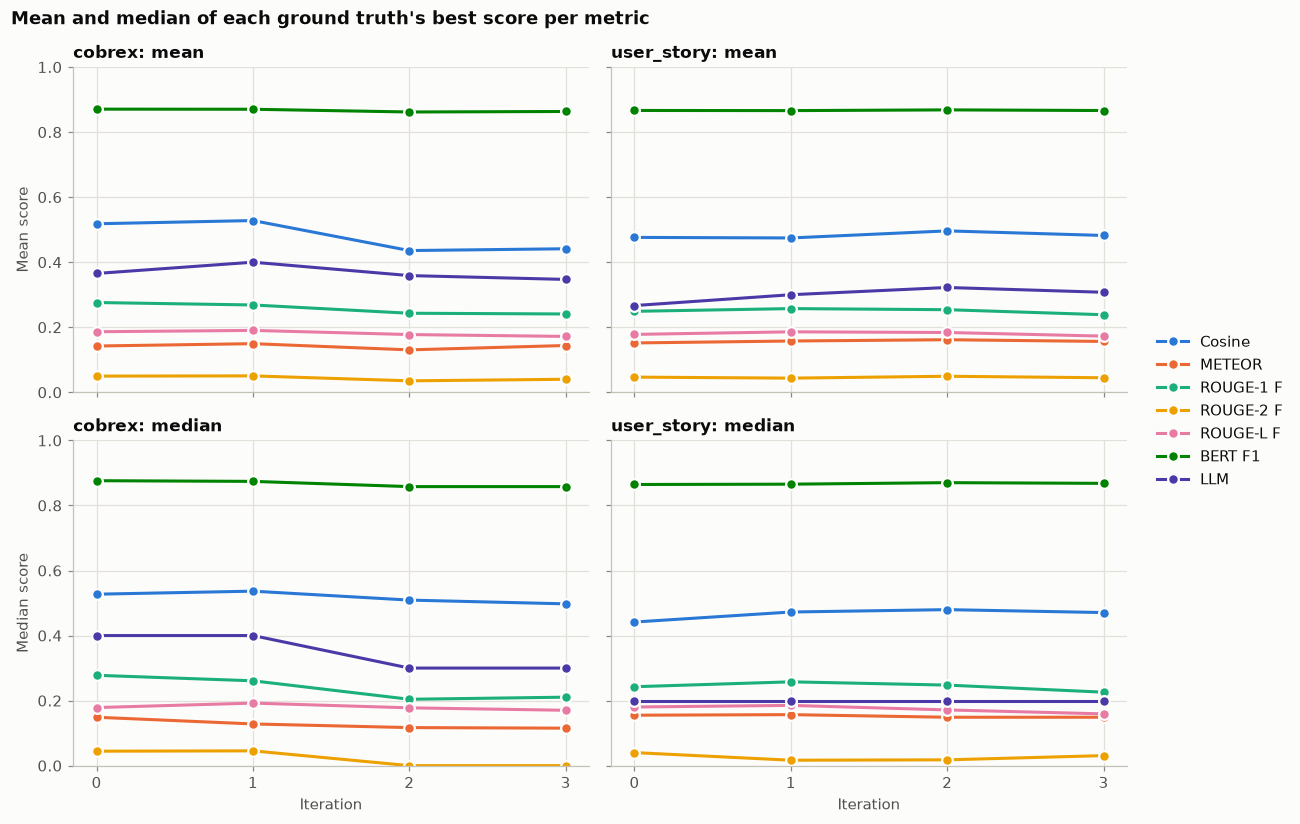

Ground truths behind each row: {('cobrex', 0): 13, ('cobrex', 1): 13, ('cobrex', 2): 17, ('cobrex', 3): 17, ('user_story', 0): 18, ('user_story', 1): 20, ('user_story', 2): 18, ('user_story', 3): 20}


Cosine        METEOR        ROUGE-1 F         \
                          mean median   mean median      mean median   
prompt_format iteration                                                
cobrex        0          0.518  0.527  0.142  0.149     0.276  0.278   
              1          0.528  0.537  0.149  0.128     0.269  0.261   
              2          0.436  0.509  0.130  0.117     0.243  0.204   
              3          0.441  0.497  0.144  0.115     0.241  0.211   
user_story    0          0.476  0.442  0.152  0.155     0.249  0.243   
              1          0.475  0.472  0.158  0.157     0.257  0.258   
              2          0.496  0.480  0.162  0.149     0.254  0.248   
              3          0.482  0.471  0.156  0.149     0.238  0.226   

                        ROUGE-2 F        ROUGE-L F        BERT F1         \
                             mean median      mean median    mean median   
prompt_format iteration                                                    
cobrex        0             0.050  0.044     0.186  0.179   0.871  0.876   
              1             0.050  0.045     0.190  0.192   0.870  0.874   
              2             0.035  0.000     0.178  0.178   0.862  0.858   
              3             0.040  0.000     0.172  0.170   0.863  0.858   
user_story    0             0.047  0.040     0.178  0.180   0.867  0.865   
              1             0.044  0.017     0.186  0.185   0.866  0.865   
              2             0.049  0.018     0.184  0.171   0.868  0.870   
              3             0.045  0.031     0.173  0.159   0.866  0.868   

                           LLM         
                          mean median  
prompt_format iteration                
cobrex        0          0.365    0.4  
              1          0.400    0.4  
              2          0.359    0.3  
              3          0.347    0.3  
user_story    0          0.267    0.2  
              1          0.300    0.2  
              2          0.322    0.2  
              3          0.308    0.2

In [12]:
best_per_truth = data.groupby(KEYS + ['file', 'ground_truth'])[list(METRICS)].max().reset_index()
best_stats = summarise(best_per_truth)

plot_metrics(best_stats, 'Mean and median of each ground truth\'s best score per metric')
print('Ground truths behind each row:', best_per_truth.groupby(KEYS).size().to_dict())
side_by_side(best_stats)

## 7. Cosine similarity vs each LLM score

One row of panels per prompt format and one column per LLM pass (`llm_score` is the same as the last pass, so it is not repeated). The LLM scores come in steps, which is why the dots form horizontal bands. The dark line is the average LLM score within each band of cosine similarity, and ρ is the Spearman rank correlation.

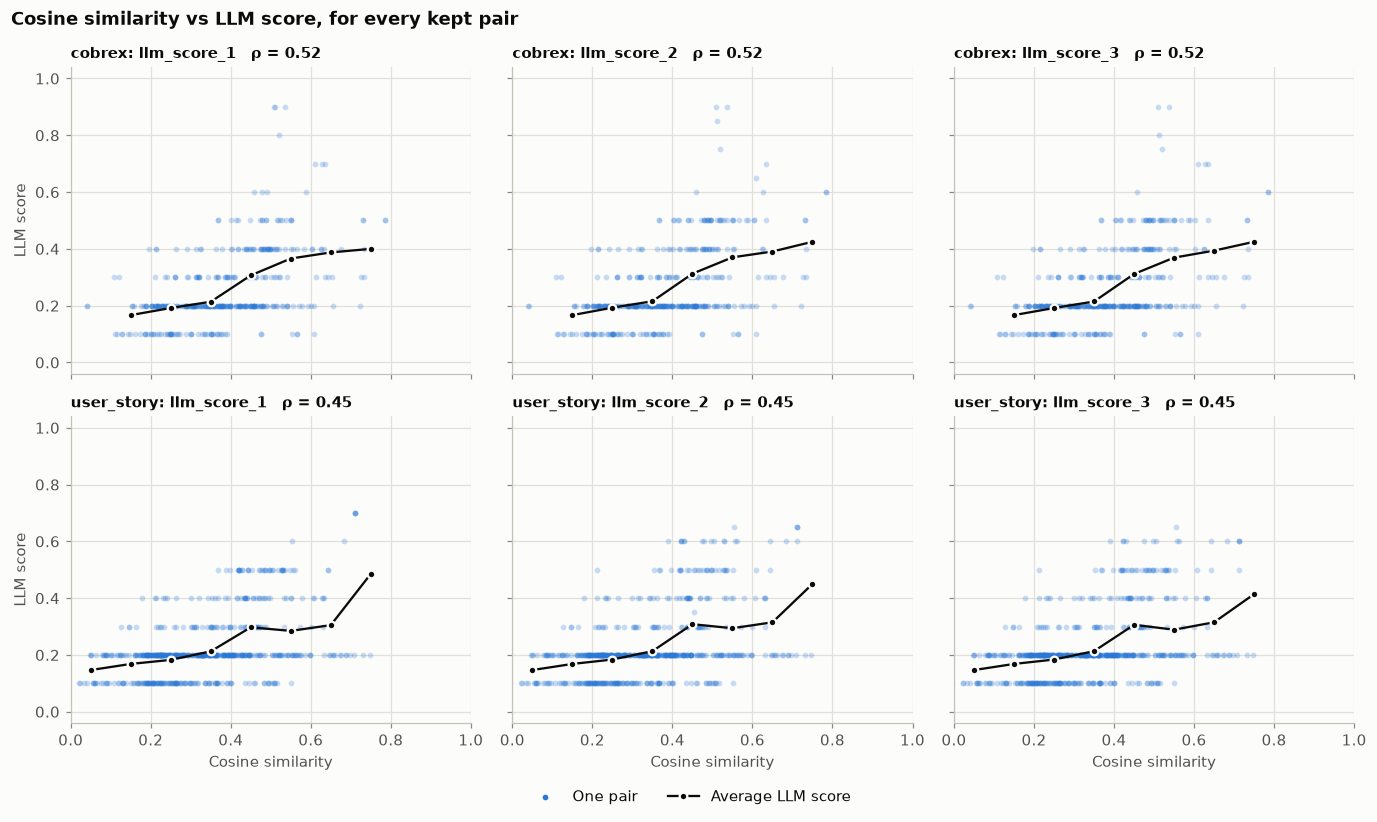

In [13]:
def spearman(x: pd.Series, y: pd.Series) -> float:
    #Spearman rank correlation: the Pearson correlation of the ranks
    return x.rank().corr(y.rank())

def binned_mean(x: pd.Series, y: pd.Series, bins: int = 10, minimum: int = 5) -> pd.Series:
    #Average of y within equal-width bands of x, skipping bands with too few points
    bands = pd.cut(x, np.linspace(0, 1, bins + 1), include_lowest = True)
    grouped = y.groupby(bands, observed = True)
    means = grouped.mean()[grouped.size() >= minimum]
    means.index = [band.mid for band in means.index]
    return means

fig, axes = plt.subplots(len(PROMPT_FORMATS), len(LLM_PASSES), figsize = (4.2 * len(LLM_PASSES), 3.6 * len(PROMPT_FORMATS)),
                         sharex = True, sharey = True, squeeze = False)

for row, prompt_format in zip(axes, PROMPT_FORMATS):
    subset = data[data['prompt_format'] == prompt_format]
    for ax, column in zip(row, LLM_PASSES):
        ax.scatter(subset['cosine'], subset[column], s = 14, color = COLOURS[0], alpha = 0.25, linewidths = 0, label = 'One pair')
        trend = binned_mean(subset['cosine'], subset[column])
        ax.plot(trend.index, trend.values, color = INK, linewidth = 1.5, marker = 'o', markersize = 5, label = 'Average LLM score')
        ax.set_title(f'{prompt_format}: {column}   ρ = {spearman(subset["cosine"], subset[column]):.2f}', fontsize = 10)
        ax.set_xlim(0, 1)
        ax.set_ylim(-0.04, 1.04)

for ax in axes[-1]:
    ax.set_xlabel('Cosine similarity')
for ax in axes[:, 0]:
    ax.set_ylabel('LLM score')

handles, labels = axes[0][0].get_legend_handles_labels()
legend = fig.legend(handles, labels, loc = 'lower center', ncol = 2, bbox_to_anchor = (0.5, -0.04))
legend.legend_handles[0].set_alpha(1)
fig.suptitle('Cosine similarity vs LLM score, for every kept pair', x = 0.01, ha = 'left', fontsize = 12, fontweight = 'bold')
fig.tight_layout()
plt.show()

In [14]:
#Spearman correlation between cosine similarity and each LLM score, per file
rows = []
for (prompt_format, iteration), group in data.groupby(KEYS):
    rows.append({'prompt_format': prompt_format, 'iteration': iteration, 'pairs': len(group),
                 **{column: spearman(group['cosine'], group[column]) for column in LLM_PASSES}})

pd.DataFrame(rows).set_index(KEYS).round(3)

pairs  llm_score_1  llm_score_2  llm_score_3
prompt_format iteration                                              
cobrex        0            101        0.512        0.517        0.514
              1             91        0.437        0.441        0.441
              2             98        0.556        0.553        0.559
              3            112        0.536        0.535        0.536
user_story    0            145        0.417        0.418        0.417
              1            164        0.446        0.432        0.432
              2            160        0.519        0.511        0.511
              3            169        0.435        0.426        0.425